# 09. Multi-Task Fine-Tuning: GABSA + Management Summary (Qwen2.5-3B)

Notebook ini adalah versi perbaikan dari `08_multitask_finetuning_gabsa_summary.ipynb`, menggabungkan mekanisme terbaik dari notebook 06 (ABSA) dan menambahkan Task B (Summary Generation) secara terstruktur.

**Dua Tugas Utama:**
1. **Task A — GABSA Extraction:** Mengekstrak aspek, sentimen, dan bukti teks dari ulasan.
2. **Task B — Management Summary:** Menghasilkan laporan analitik strategis dari statistik agregat ulasan.

**Perbaikan dari versi sebelumnya (08):**
- Train / Validation / Test split formal (70 / 15 / 15)
- F1-Score evaluasi untuk Task A (aspect & pair)
- ROUGE evaluasi untuk Task B (summary generation)
- `ReviewRecord` dataclass untuk pengelolaan data GABSA
- Task-proportional sampling (rasio Task A : Task B dikontrol)
- External kamus normalisasi dari CSV
- Robust JSON parsing saat inferensi
- Task-aware preprocessing (GABSA = preprocess agresif, Summary = preprocess ringan)
- Packing dinonaktifkan untuk menjaga integritas multi-task sequence

**Stack:**
- Model: `unsloth/Qwen2.5-3B-Instruct-bnb-4bit`
- Training: QLoRA 4-bit + SFTTrainer (Unsloth)
- Format: **ChatML format** (`<|im_start|>role
content<|im_end|>`) via `get_chat_template`

## 0. Install Dependencies

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install trl bitsandbytes unsloth

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.3/61.3 kB 5.6 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of unsloth to determine which version is compatible with other requirements. This could take a while.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.3/61.3 kB 6.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 6.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.9/58.9 kB 6.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.9/58.9 kB 6.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.9/58.9 kB 6.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.9/58.9 kB 6.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.9/58.9 kB 5.6 MB/s eta 0:00:00
INFO: pip is still looking at multiple versions of unsloth to determine which version is compatible with other requirements. This could take a while.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.9/58.9 kB 5.8 MB/

In [ ]:
!pip install bert-score rouge-score

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 4.1 MB/s eta 0:00:00
  Created wheel for rouge-score: filename=rouge_score-0.1.2-py3-none-any.whl size=24934 sha256=a3a7c8282bd4a9b2e72cd1ba53c749bc095a04dd0d08184db79f2e8dd26852c4
  Stored in directory: /root/.cache/pip/wheels/85/9d/af/01feefbe7d55ef5468796f0c68225b6788e85d9d0a281e7a70
Successfully built rouge-score


## 1. Imports & Device Setup

In [ ]:
import os
import json
import re
import random
import torch
import pandas as pd
import numpy as np
from tqdm import tqdm
from dataclasses import dataclass, field,  asdict
from typing import List, Dict, Optional
from datasets import Dataset
from unsloth import FastLanguageModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


🦥 Unsloth Zoo will now patch everything to make training faster!


Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Using device: cuda


## 2. Advanced Preprocessing Pipeline

Sama persis dengan notebook 06, ditambah dukungan `mapping_path` untuk kamus normalisasi eksternal.

In [ ]:
class TextCleaner:
    def __init__(self):
        self.url_pattern = re.compile(r'https?://\S+|www\.\S+')
        self.html_pattern = re.compile(r'<.*?>')
        self.clean_pattern = re.compile(r'[^a-zA-Z0-9\s!?.,]')

    def clean(self, text: str) -> str:
        if not isinstance(text, str): return ""
        text = text.lower()
        text = self.url_pattern.sub('', text)
        text = self.html_pattern.sub('', text)
        text = re.sub(r'([!?.]){2,}', r'\1', text)
        text = re.sub(r'[^\x00-\x7f]', r' ', text)
        text = self.clean_pattern.sub(' ', text)
        text = re.sub(r'\s+', ' ', text).strip()
        return text


class IndonesianNormalizer:
    """Normalisasi dinonaktifkan sesuai permintaan user."""
    def __init__(self, mapping_path: Optional[str] = None):
        pass

    def normalize(self, text: str) -> str:
        return text


class PreprocessingPipeline:
    """Pipeline dengan cleaning saja, tanpa normalisasi slang."""
    def __init__(self, mapping_path: Optional[str] = None):
        self.cleaner = TextCleaner()
        self.normalizer = IndonesianNormalizer(mapping_path)

    def preprocess(self, text: str, metadata: Optional[dict] = None) -> Optional[str]:
        if not text: return None
        if metadata and 'Comments' in metadata:
            for comment in metadata.get('Comments', []):
                if isinstance(comment, str) and "tidak jelas" in comment.lower():
                    return None

        cleaned = self.cleaner.clean(text)

        if len(cleaned.split()) < 8:
            return None
        return cleaned

    def normalize_string(self, text: str) -> str:
        if not text: return ""
        return self.cleaner.clean(text)

## 3. Data Structures & Loading

### 3a. Task A — GABSA (dari Doccano JSONL)

In [ ]:
@dataclass
class ReviewRecord:
    """Merepresentasikan satu ulasan GABSA yang sudah diproses."""
    text_clean: str
    labels: List[Dict]  # [{"aspect": ..., "sentiment": ..., "evidence": ...}]


def load_gabsa_data(
    file_path: str,
    mapping_path: Optional[str] = None
) -> List[ReviewRecord]:
    """Memuat dan memproses dataset GABSA dari file Doccano JSONL."""
    pipeline = PreprocessingPipeline(mapping_path)
    records = []
    skipped = 0

    with open(file_path, "r", encoding="utf-8") as f:
        for line in f:
            payload = json.loads(line)
            text = payload.get("text", "")
            clean_text = pipeline.preprocess(text, payload)

            if clean_text is None:
                skipped += 1
                continue

            labels = []
            for s, e, label_str in payload.get("label", []):
                if "__" not in label_str:
                    continue
                aspect, sentiment = label_str.split("__", 1)
                evidence_clean = pipeline.normalize_string(text[s:e])
                labels.append({
                    "aspect": aspect.lower(),
                    "sentiment": sentiment.lower(),
                    "evidence": evidence_clean
                })

            records.append(ReviewRecord(text_clean=clean_text, labels=labels))

    print(f"GABSA: {len(records)} records dimuat, {skipped} dilewati.")
    return records


def train_valid_test_split(
    records: list,
    train_ratio: float = 0.70,
    valid_ratio: float = 0.15,
    seed: int = 42
) -> Dict[str, list]:
    """Split data menjadi Train / Valid / Test."""
    shuffled = list(records)
    random.Random(seed).shuffle(shuffled)
    n = len(shuffled)
    tr_end = int(n * train_ratio)
    va_end = int(n * (train_ratio + valid_ratio))
    return {
        "train": shuffled[:tr_end],
        "valid": shuffled[tr_end:va_end],
        "test":  shuffled[va_end:]
    }

### 3b. Task B — Management Summary (dari Excel)

In [ ]:
@dataclass
class SummaryRecord:
    """Merepresentasikan satu pasangan input-output untuk task summary."""
    input_stats: str   # JSON string statistik agregat
    target_summary: str


def load_summary_data(
    file_path: str,
    mapping_path: Optional[str] = None
) -> List[SummaryRecord]:
    """
    Memuat dataset summary dari Excel.
    Kolom yang diharapkan: 'input_stats' (JSON string), 'target_summary' (teks).
    Snippet dalam input_stats dinormalisasi ringan agar konsisten.
    """
    pipeline = PreprocessingPipeline(mapping_path)
    records = []
    df = pd.read_excel(file_path)

    required_cols = {"input_stats", "target_summary"}
    if not required_cols.issubset(df.columns):
        raise ValueError(f"Excel harus memiliki kolom: {required_cols}. Ditemukan: {set(df.columns)}")

    for _, row in df.iterrows():
        try:
            stats_obj = json.loads(row["input_stats"])
        except (json.JSONDecodeError, TypeError):
            continue

        # Normalisasi ringan pada snippet teks di dalam JSON
        for section in ["key_snippets"]:
            if section in stats_obj:
                for key in ["positive_highlights", "negative_highlights"]:
                    if key in stats_obj[section] and isinstance(stats_obj[section][key], list):
                        stats_obj[section][key] = [
                            pipeline.normalize_string(s) for s in stats_obj[section][key]
                        ]

        target = str(row["target_summary"]).strip()
        if not target:
            continue

        records.append(SummaryRecord(
            input_stats=json.dumps(stats_obj, ensure_ascii=False),
            target_summary=target
        ))

    print(f"Summary: {len(records)} records dimuat dari '{file_path}'.")
    return records

## 4. Konfigurasi Model (Qwen2.5-3B via Unsloth)

In [ ]:
from unsloth import FastLanguageModel
from unsloth.chat_templates import get_chat_template

MODEL_NAME    = "unsloth/Qwen2.5-3B-Instruct-bnb-4bit"
MAX_SEQ_LEN   = 2048
LOAD_IN_4BIT  = True

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name    = MODEL_NAME,
    max_seq_length= MAX_SEQ_LEN,
    dtype         = None,
    load_in_4bit  = LOAD_IN_4BIT,
)

tokenizer = get_chat_template(
    tokenizer,
    chat_template = "qwen-2.5",
)

model = FastLanguageModel.get_peft_model(
    model,
    r               = 16,
    target_modules  = ["q_proj", "k_proj", "v_proj", "o_proj",
                       "gate_proj", "up_proj", "down_proj"],
    lora_alpha      = 32,
    lora_dropout    = 0.05,
    bias            = "none",
    use_gradient_checkpointing = "unsloth",
    random_state    = 3407,
)
model.print_trainable_parameters()

==((====))==  Unsloth 2025.11.1: Fast Qwen2 patching. Transformers: 4.57.2.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


model.safetensors:   0%|          | 0.00/2.05G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

...

added_tokens.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

Unsloth: Dropout = 0 is supported for fast patching. You are using dropout = 0.05.
Unsloth will patch all other layers, except LoRA matrices, causing a performance hit.
Unsloth 2025.11.1 patched 36 layers with 0 QKV layers, 0 O layers and 0 MLP layers.


trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607


## 5. Prompt Formatting

Keduanya menggunakan format **ChatML** — model membedakan task lewat teks `system` prompt.

In [ ]:
GABSA_SYSTEM_PROMPT = (
    "Anda adalah pakar NLP kesehatan. Ekstrak aspek, sentimen, dan bukti teks dari ulasan rumah sakit "
    "ke dalam format JSON yang valid."
)
SUMMARY_SYSTEM_PROMPT = (
    "Anda adalah konsultan manajemen rumah sakit senior. "
    "Buatlah ringkasan analitik strategis dalam Bahasa Indonesia dengan struktur Ringkasan Eksekutif, Keunggulan (Strengths), Masalah Kritis (Pain Points), dan Rekomendasi Strategis. Berdasarkan statistik ulasan yang diberikan."
)

def format_gabsa(record: ReviewRecord) -> str:
    messages = [
        {"role": "system", "content": GABSA_SYSTEM_PROMPT},
        {"role": "user", "content": record.text_clean},
        {"role": "assistant", "content": json.dumps({"labels": record.labels}, ensure_ascii=False)}
    ]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)


def format_summary(record: SummaryRecord) -> str:
    messages = [
        {"role": "system", "content": SUMMARY_SYSTEM_PROMPT},
        {"role": "user", "content": record.input_stats},
        {"role": "assistant", "content": record.target_summary}
    ]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)


# ── Preview Format ────────────────────────────────────────────────────────────
print("=== PREVIEW TASK A: GABSA ===")
dummy_gabsa = ReviewRecord(
    text_clean="suster di sini ramah banget, tapi harganya mahal tidak umum.",
    labels=[
        {"aspect": "pelayanan", "sentiment": "positif", "evidence": "suster di sini ramah banget"},
        {"aspect": "biaya", "sentiment": "negatif", "evidence": "harganya mahal tidak umum"}
    ]
)
print(format_gabsa(dummy_gabsa))

print("\n" + "="*30 + "\n")

print("=== PREVIEW TASK B: SUMMARY ===")
dummy_summary = SummaryRecord(
    input_stats=json.dumps({"pelayanan": {"positif": 10, "negatif": 2}, "biaya": {"positif": 1, "negatif": 5}}),
    target_summary="Secara keseluruhan pelayanan sangat baik namun biaya menjadi keluhan utama."
)
print(format_summary(dummy_summary))

=== PREVIEW TASK A: GABSA ===
<|im_start|>system
Anda adalah pakar NLP kesehatan. Ekstrak aspek, sentimen, dan bukti teks dari ulasan rumah sakit ke dalam format JSON yang valid.<|im_end|>
<|im_start|>user
suster di sini ramah banget, tapi harganya mahal tidak umum.<|im_end|>
<|im_start|>assistant
{"labels": [{"aspect": "pelayanan", "sentiment": "positif", "evidence": "suster di sini ramah banget"}, {"aspect": "biaya", "sentiment": "negatif", "evidence": "harganya mahal tidak umum"}]}<|im_end|>



=== PREVIEW TASK B: SUMMARY ===
<|im_start|>system
Anda adalah konsultan manajemen rumah sakit senior. Buatlah ringkasan analitik strategis dalam Bahasa Indonesia dengan struktur Ringkasan Eksekutif, Keunggulan (Strengths), Masalah Kritis (Pain Points), dan Rekomendasi Strategis. Berdasarkan statistik ulasan yang diberikan.<|im_end|>
<|im_start|>user
{"pelayanan": {"positif": 10, "negatif": 2}, "biaya": {"positif": 1, "negatif": 5}}<|im_end|>
<|im_start|>assistant
Secara keseluruhan pelayanan

## 6. Load Data & Build Multi-Task Dataset

Dataset training digabung dengan rasio yang dikontrol agar Task A dan Task B seimbang.

In [ ]:
# ── Path konfigurasi ──────────────────────────────────────────────────────────
GABSA_PATH   = "/content/drive/MyDrive/Skripsi_v2/data/absa_labeled_data_combined.jsonl"
SUMMARY_PATH = "/content/drive/MyDrive/Skripsi_v2/data/summary_data_result.xlsx"
KAMUS_PATH   = "/content/drive/MyDrive/Skripsi_v2/data/kamus_normalisasi.csv"  # opsional, bisa None

# ── Load data ─────────────────────────────────────────────────────────────────
gabsa_records   = load_gabsa_data(GABSA_PATH, mapping_path=KAMUS_PATH)
summary_records = load_summary_data(SUMMARY_PATH, mapping_path=KAMUS_PATH)

# ── Split GABSA (70/15/15) with Stratified Sampling ───────────────────────────
from sklearn.model_selection import train_test_split

# Tentukan label stratifikasi (misal berdasarkan aspek pertama atau dominan)
# Jika tidak ada label, gunakan 'none'
def get_stratify_label(record):
    if not record.labels:
        return "none"
    return record.labels[0]['aspect']

stratify_labels = [get_stratify_label(r) for r in gabsa_records]

# Split 1: Train vs (Valid + Test)
train_idx, temp_idx = train_test_split(
    range(len(gabsa_records)),
    test_size=0.30,
    stratify=stratify_labels,
    random_state=42
)

# Split 2: Valid vs Test dari sisa 30%
temp_labels = [stratify_labels[i] for i in temp_idx]
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=temp_labels,
    random_state=42
)

gabsa_splits = {
    "train": [gabsa_records[i] for i in train_idx],
    "valid": [gabsa_records[i] for i in val_idx],
    "test":  [gabsa_records[i] for i in test_idx]
}

print(f"GABSA splits (Stratified) — Train: {len(gabsa_splits['train'])}, "
      f"Valid: {len(gabsa_splits['valid'])}, Test: {len(gabsa_splits['test'])}")

# ── Split Summary (70/15/15) ──────────────────────────────────────────────────
summary_splits = train_valid_test_split(summary_records)
print(f"Summary splits — Train: {len(summary_splits['train'])}, "
      f"Valid: {len(summary_splits['valid'])}, Test: {len(summary_splits['test'])}")

# ── Format & Gabung untuk Training ───────────────────────────────────────────
train_prompts = (
    [format_gabsa(r) for r in gabsa_splits['train']] +
    [format_summary(r) for r in summary_splits['train']]
)
random.shuffle(train_prompts)  # Acak setelah digabung

train_dataset = Dataset.from_dict({"text": train_prompts})
print(f"\nTotal training samples: {len(train_dataset)} "
      f"(GABSA: {len(gabsa_splits['train'])}, Summary: {len(summary_splits['train'])})")

GABSA: 7900 records dimuat, 26 dilewati.
Summary: 100 records dimuat dari '/content/drive/MyDrive/Skripsi_v2/data/summary_data_result.xlsx'.
GABSA splits (Stratified) — Train: 5530, Valid: 1185, Test: 1185
Summary splits — Train: 70, Valid: 15, Test: 15

Total training samples: 5600 (GABSA: 5530, Summary: 70)


In [ ]:
import os
from dataclasses import asdict

# --- Path Output ---
OUTPUT_FOLDER = "/content/drive/MyDrive/Skripsi_v2/data/splits_v3/"
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

def save_gabsa_split(records, filename):
    path = os.path.join(OUTPUT_FOLDER, filename)
    with open(path, 'w', encoding='utf-8') as f:
        for rec in records:
            # asdict mengubah dataclass ReviewRecord menjadi dictionary
            f.write(json.dumps(asdict(rec), ensure_ascii=False) + '\n')
    print(f"Saved GABSA split to: {path}")

def save_summary_split(records, filename):
    path = os.path.join(OUTPUT_FOLDER, filename)
    # Ubah list of SummaryRecord dataclass menjadi DataFrame
    data_dict = [asdict(r) for r in records]
    pd.DataFrame(data_dict).to_excel(path, index=False)
    print(f"Saved Summary split to: {path}")

# --- Eksekusi Penyimpanan ---
print("Menyimpan data split GABSA...")
for split_name, records in gabsa_splits.items():
    save_gabsa_split(records, f"gabsa_{split_name}.jsonl")

print("\nMenyimpan data split Summary...")
for split_name, records in summary_splits.items():
    save_summary_split(records, f"summary_{split_name}.xlsx")

print("\nSemua data split berhasil disimpan di folder:", OUTPUT_FOLDER)

Menyimpan data split GABSA...
Saved GABSA split to: /content/drive/MyDrive/Skripsi_v2/data/splits_v3/gabsa_train.jsonl
Saved GABSA split to: /content/drive/MyDrive/Skripsi_v2/data/splits_v3/gabsa_valid.jsonl
Saved GABSA split to: /content/drive/MyDrive/Skripsi_v2/data/splits_v3/gabsa_test.jsonl

Menyimpan data split Summary...
Saved Summary split to: /content/drive/MyDrive/Skripsi_v2/data/splits_v3/summary_train.xlsx
Saved Summary split to: /content/drive/MyDrive/Skripsi_v2/data/splits_v3/summary_valid.xlsx
Saved Summary split to: /content/drive/MyDrive/Skripsi_v2/data/splits_v3/summary_test.xlsx

Semua data split berhasil disimpan di folder: /content/drive/MyDrive/Skripsi_v2/data/splits_v3/


## 7. Fine-Tuning

In [ ]:
from trl import SFTTrainer, SFTConfig

# Mempersiapkan dataset validasi
valid_prompts = (
    [format_gabsa(r) for r in gabsa_splits['valid']] +
    [format_summary(r) for r in summary_splits['valid']]
)
valid_dataset = Dataset.from_dict({"text": valid_prompts})

sft_config = SFTConfig(
    per_device_train_batch_size    = 2,
    gradient_accumulation_steps    = 4,
    warmup_steps                   = 20,
    num_train_epochs               = 3,
    learning_rate                  = 2e-4,
    fp16                           = not torch.cuda.is_bf16_supported(),
    bf16                           = torch.cuda.is_bf16_supported(),
    logging_steps                  = 10,
    eval_strategy                  = "steps",
    eval_steps                     = 20,
    optim                          = "adamw_8bit",
    weight_decay                   = 0.01,
    lr_scheduler_type              = "linear",
    seed                           = 3407,
    output_dir                     = "outputs_multitask_3b",
    dataset_text_field             = "text",
    max_seq_length                 = MAX_SEQ_LEN,
    packing                        = False,
    dataset_num_proc               = 2,
)

trainer = SFTTrainer(
    model           = model,
    train_dataset   = train_dataset,
    eval_dataset    = valid_dataset,
    processing_class = tokenizer,
    args            = sft_config,
)

trainer_stats = trainer.train()

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/5600 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/1200 [00:00<?, ? examples/s]

The model is already on multiple devices. Skipping the move to device specified in `args`.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 5,600 | Num Epochs = 3 | Total steps = 2,100
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 29,933,568 of 3,115,872,256 (0.96% trained)
/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 3


wandb: You chose "Don't visualize my results"
wandb: Using W&B in offline mode.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


wandb: Detected [huggingface_hub.inference, openai] in use.
wandb: Use W&B Weave for improved LLM call tracing. Install Weave with `pip install weave` then add `import weave` to the top of your script.
wandb: For more information, check out the docs at: https://weave-docs.wandb.ai


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,Validation Loss


Unsloth: Not an error, but Qwen2ForCausalLM does not accept `num_items_in_batch`.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient


In [ ]:
# --- Simpan Log Training ke CSV ---
log_history = pd.DataFrame(trainer.state.log_history)
log_csv_path = "/content/drive/MyDrive/Skripsi_v2/evaluasi/qwen2.5-3b-unnormalized/training_logs.csv"
log_history.to_csv(log_csv_path, index=False)
print(f"Log training (loss, dll) berhasil disimpan di: {log_csv_path}")

Log training (loss, dll) berhasil disimpan di: /content/drive/MyDrive/Skripsi_v2/evaluasi/qwen2.5-3b-unnormalized/training_logs.csv


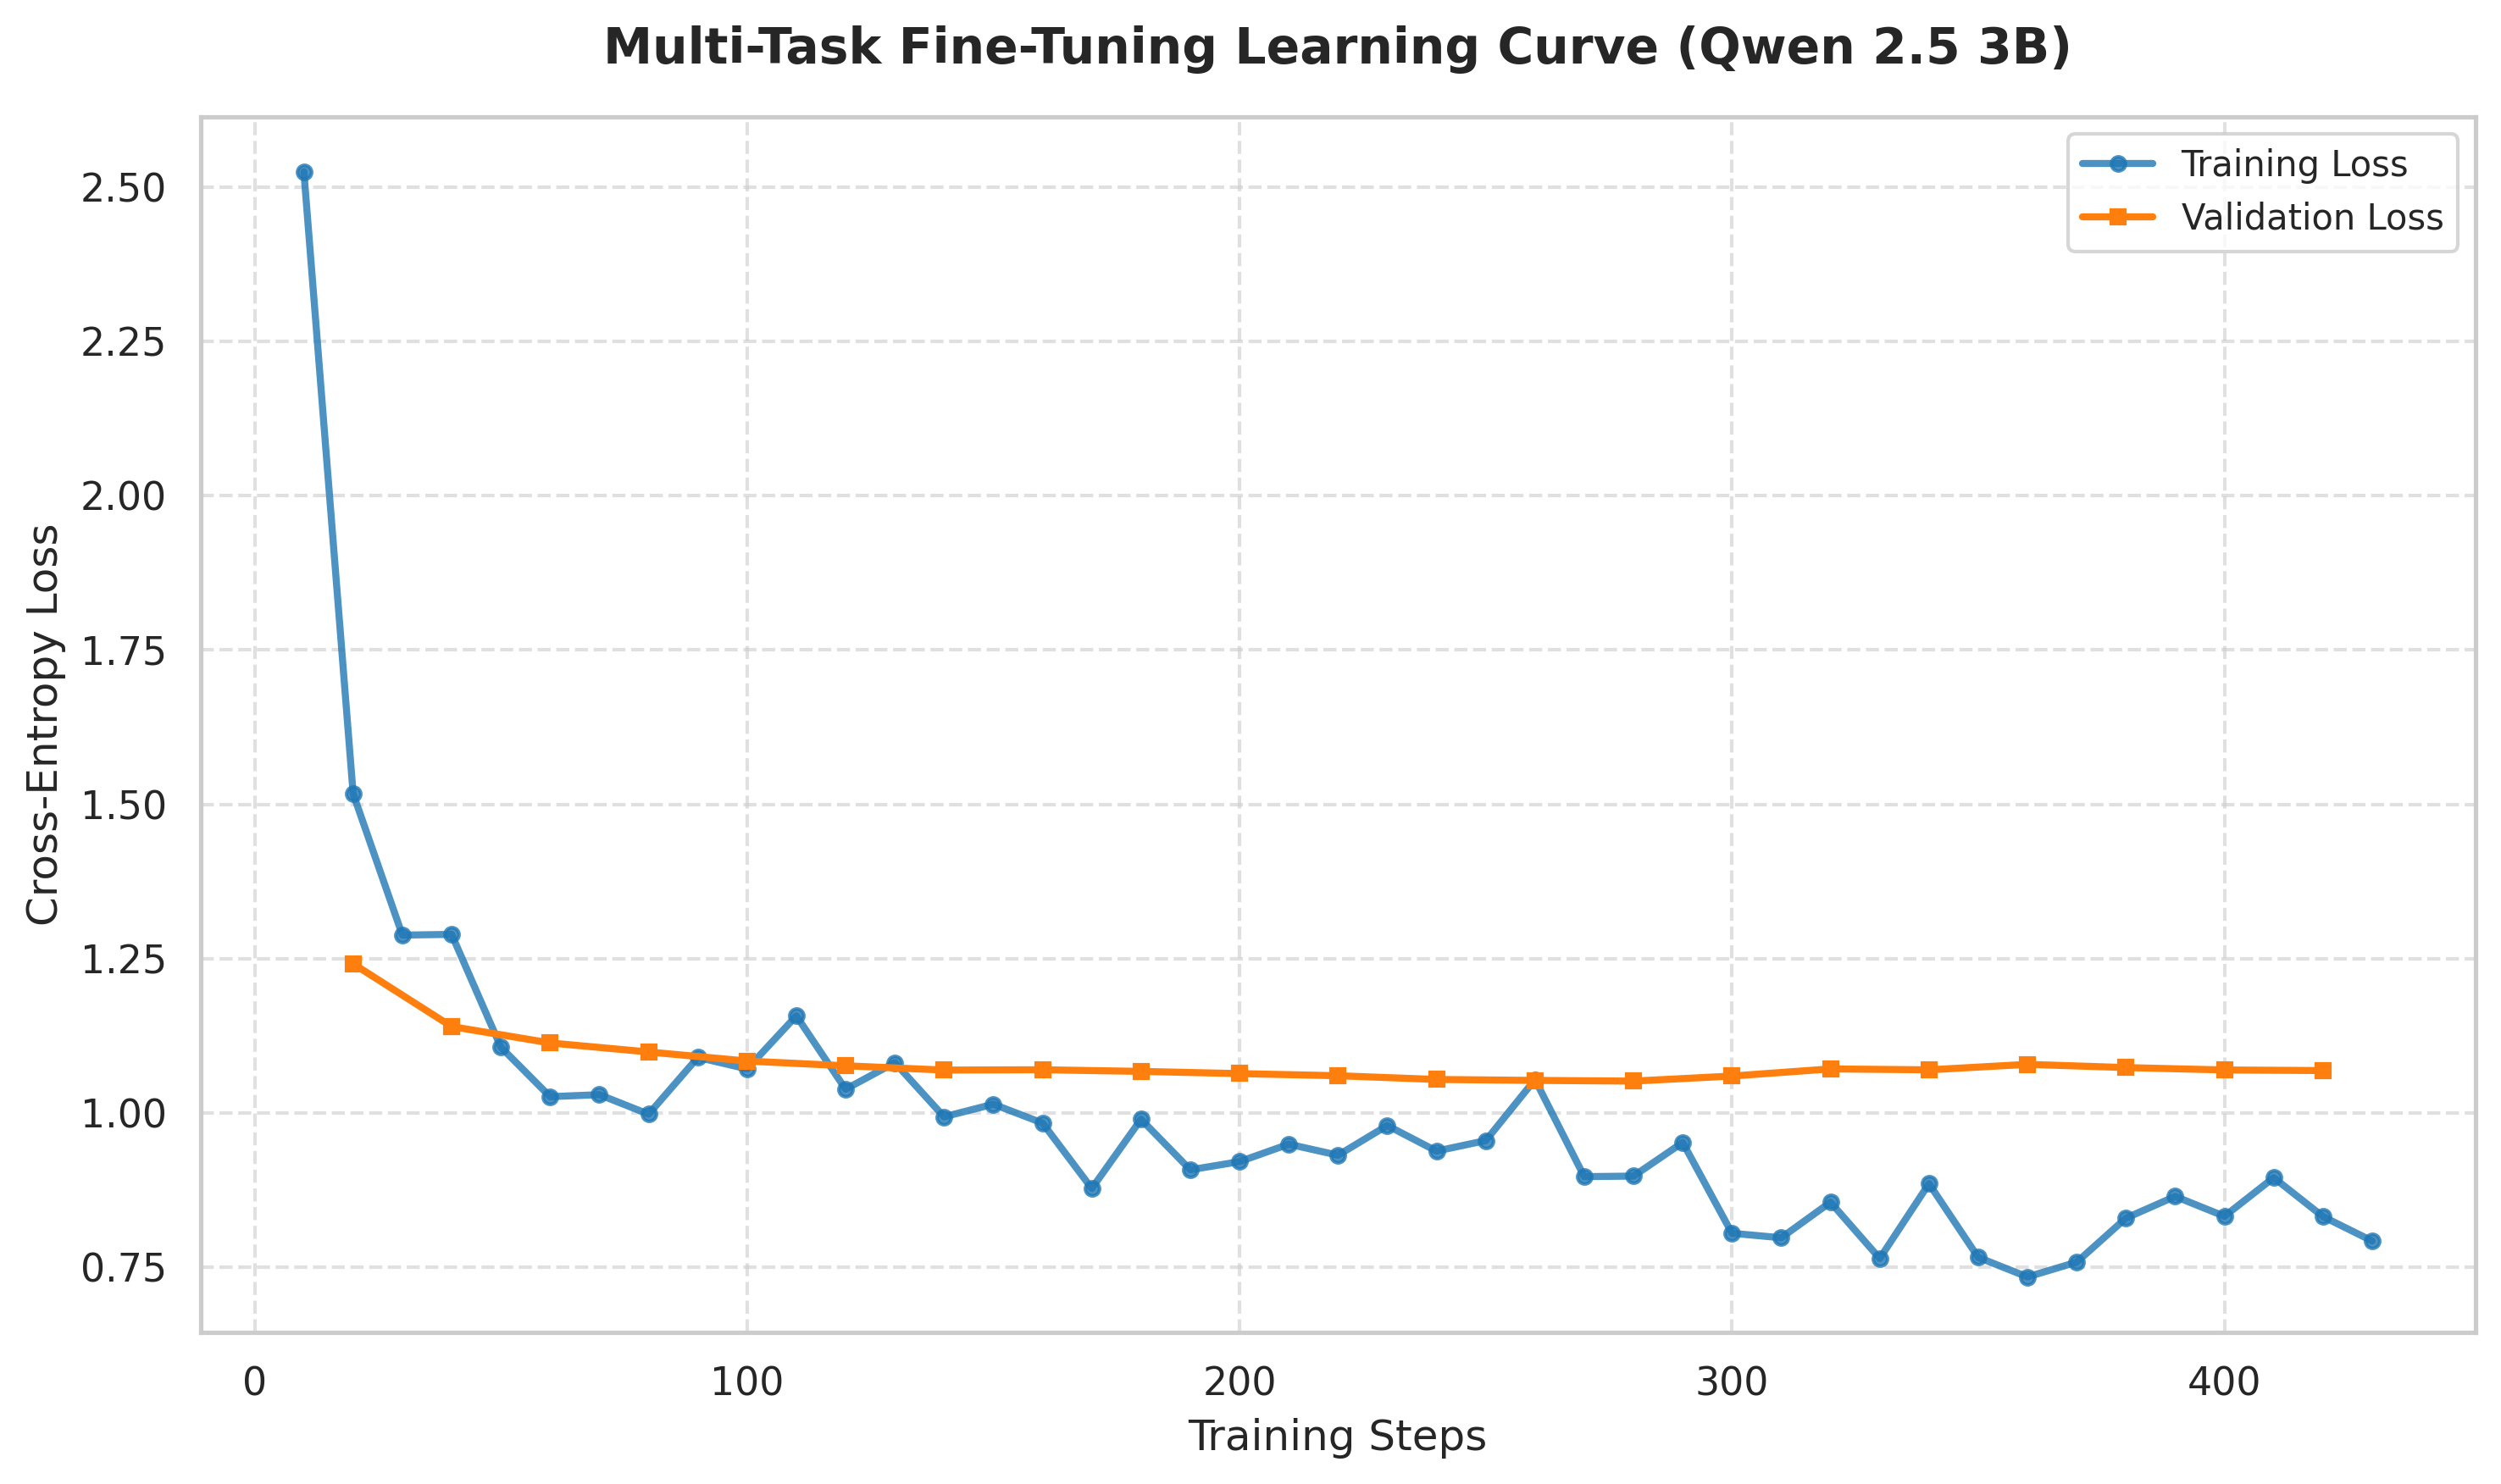

Visualisasi berhasil disimpan di: /content/drive/MyDrive/Skripsi_v2/evaluasi/qwen2.5-3b-unnormalized/learning_curve_scientific.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the training logs
log_csv_path = "/content/drive/MyDrive/Skripsi_v2/evaluasi/qwen2.5-3b-unnormalized/training_logs.csv"
df_logs = pd.read_csv(log_csv_path)

# 2. Extract training and validation loss data
train_loss = df_logs[df_logs['loss'].notna()][['step', 'loss']]
val_loss = df_logs[df_logs['eval_loss'].notna()][['step', 'eval_loss']]

# 3. Visualization for Academic Paper
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6), dpi=300)

# Plot Training Loss
plt.plot(train_loss['step'], train_loss['loss'],
         label='Training Loss', color='#1f77b4', linewidth=2, marker='o', markersize=4, alpha=0.8)

# Plot Validation Loss (if available)
if not val_loss.empty:
    plt.plot(val_loss['step'], val_loss['eval_loss'],
             label='Validation Loss', color='#ff7f0e', linewidth=2, marker='s', markersize=4)

# Formatting for publication
plt.title('Multi-Task Fine-Tuning Learning Curve (Qwen 2.5 3B)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Training Steps', fontsize=12)
plt.ylabel('Cross-Entropy Loss', fontsize=12)
plt.legend(fontsize=10, loc='upper right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)

# Optional: Set Y-axis limit if loss is very high initially to focus on convergence
# plt.ylim(0, 2.0)

plt.tight_layout()

# Save for paper
save_plot_path = "/content/drive/MyDrive/Skripsi_v2/evaluasi/qwen2.5-3b-unnormalized_v3/learning_curve_scientific.png"
plt.savefig(save_plot_path, bbox_inches='tight')
plt.show()

print(f"Visualisasi berhasil disimpan di: {save_plot_path}")

## 8. Evaluasi

### 8a. Evaluasi Task A — F1-Score (Aspect & Pair)

Sama persis dengan mekanisme evaluasi di notebook 06.

In [ ]:
def aggregate_metrics(
    references: List[List[Dict]],
    predictions: List[List[Dict]]
) -> Dict:
    """
    Menghitung Precision, Recall, F1 untuk:
    - aspect        : hanya nama aspek (tanpa sentimen)
    - pair (aspect + sentiment)
    """
    def to_set(labels, with_sentiment=True):
        if with_sentiment:
            return {(l['aspect'], l['sentiment']) for l in labels}
        return {(l['aspect'],) for l in labels}

    tp_a = fp_a = fn_a = 0
    tp_p = fp_p = fn_p = 0

    for ref, pred in zip(references, predictions):
        r_a, p_a = to_set(ref, False), to_set(pred, False)
        tp_a += len(r_a & p_a); fp_a += len(p_a - r_a); fn_a += len(r_a - p_a)

        r_p, p_p = to_set(ref, True), to_set(pred, True)
        tp_p += len(r_p & p_p); fp_p += len(p_p - r_p); fn_p += len(r_p - p_p)

    def prf(tp, fp, fn):
        p = tp / (tp + fp) if (tp + fp) else 0.0
        r = tp / (tp + fn) if (tp + fn) else 0.0
        f = 2 * p * r / (p + r) if (p + r) else 0.0
        return {"precision": round(p, 4), "recall": round(r, 4), "f1": round(f, 4)}

    return {
        "aspect": prf(tp_a, fp_a, fn_a),
        "pair":   prf(tp_p, fp_p, fn_p)
    }

In [ ]:
FastLanguageModel.for_inference(model)

def predict_gabsa(text_clean: str) -> List[Dict]:
    """Jalankan inferensi Task A dan parse hasil JSON."""
    messages = [
        {"role": "system", "content": GABSA_SYSTEM_PROMPT},
        {"role": "user", "content": text_clean}
    ]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

    inputs = tokenizer([prompt], return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = model.generate(**inputs, max_new_tokens=512, do_sample=False)
    decoded = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )
    # Robust JSON parsing
    try:
        match = re.search(r'\{.*\}', decoded, re.DOTALL)
        if match:
            return json.loads(match.group()).get('labels', [])
    except (json.JSONDecodeError, AttributeError):
        pass
    return []


print("Evaluasi Task A pada Test Set...")
gabsa_test   = gabsa_splits['test']
references   = [r.labels for r in gabsa_test]
predictions  = [predict_gabsa(r.text_clean) for r in tqdm(gabsa_test)]

gabsa_results = aggregate_metrics(references, predictions)
print("\n=== Task A — GABSA F1-Score ===")
print(json.dumps(gabsa_results, indent=2))

Evaluasi Task A pada Test Set...


100%|██████████| 236/236 [23:48<00:00,  6.05s/it]


=== Task A — GABSA F1-Score ===
{
  "aspect": {
    "precision": 0.7422,
    "recall": 0.7422,
    "f1": 0.7422
  },
  "pair": {
    "precision": 0.7054,
    "recall": 0.6982,
    "f1": 0.7018
  }
}


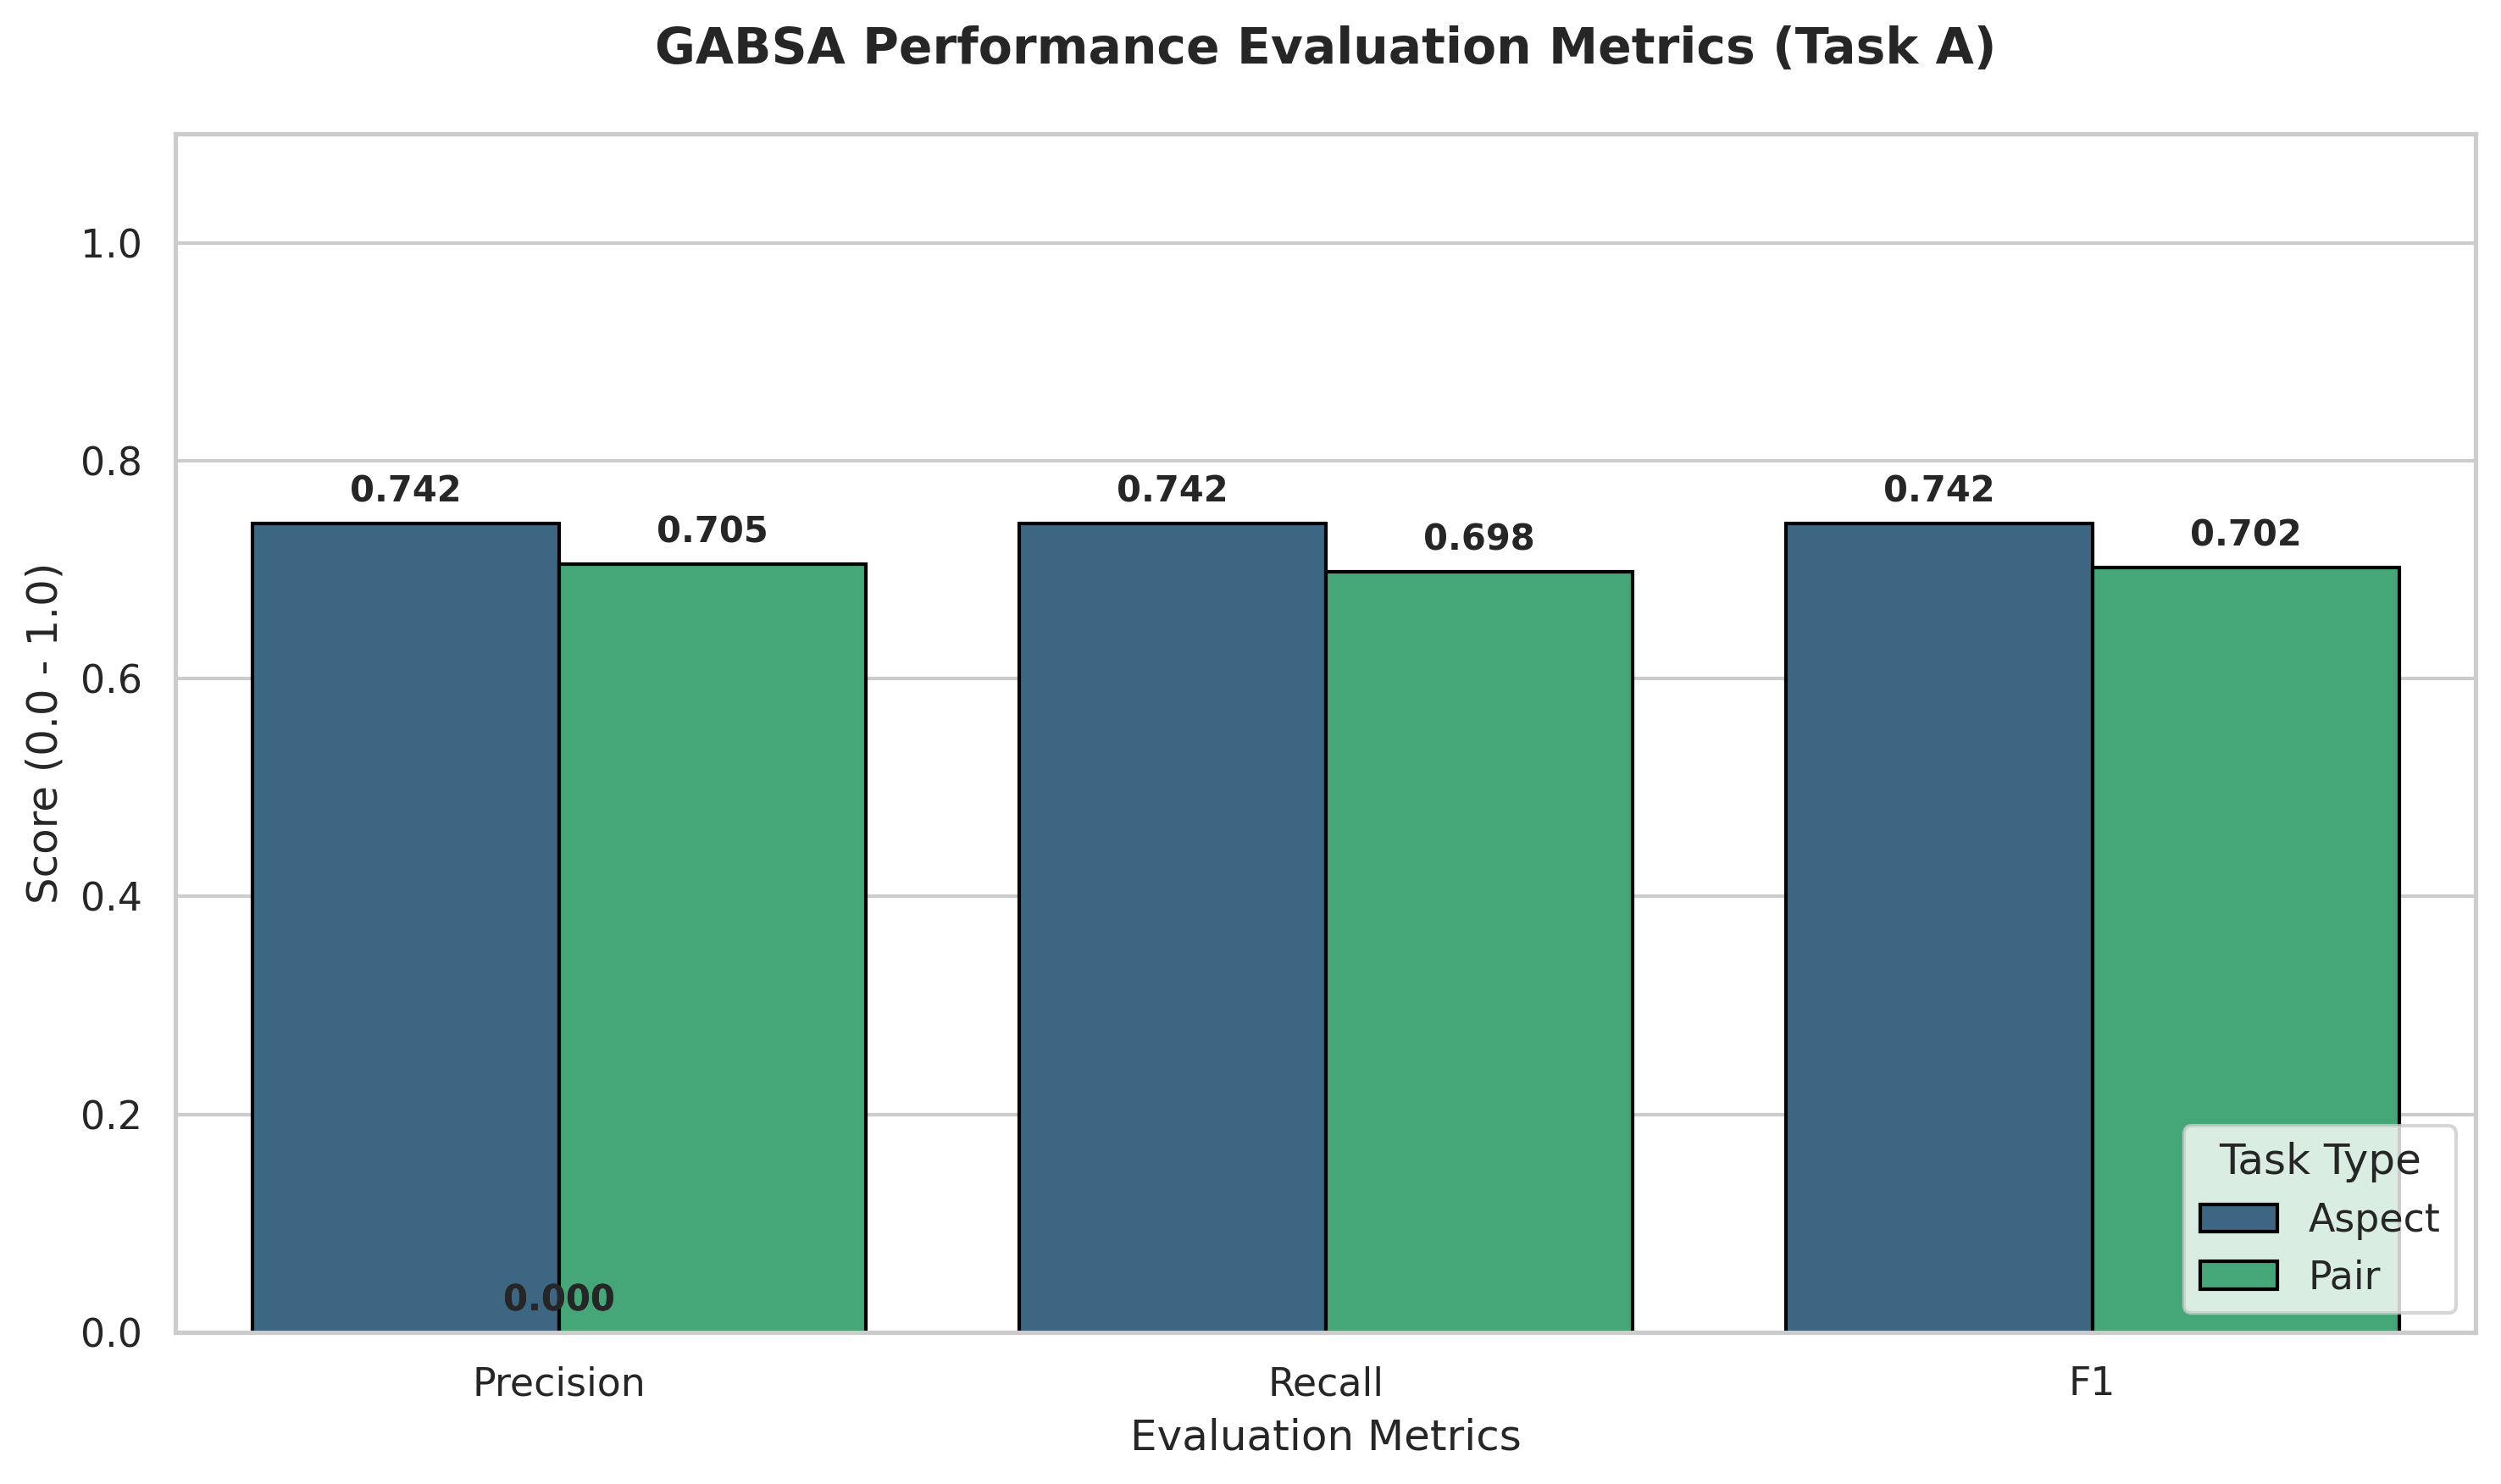

Visualisasi GABSA berhasil disimpan di: /content/drive/MyDrive/Skripsi_v2/evaluasi/qwen2.5-3b-unnormalized/gabsa_evaluation_plot.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Prepare data from gabsa_results variable
# Data format: {'aspect': {'precision': ..., 'recall': ..., 'f1': ...}, 'pair': {...}}
data = []
for category, metrics in gabsa_results.items():
    for metric_name, value in metrics.items():
        data.append({
            'Category': category.capitalize(),
            'Metric': metric_name.capitalize(),
            'Score': value
        })

df_plot = pd.DataFrame(data)

# 2. Scientific Visualization
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6), dpi=300)

ax = sns.barplot(
    data=df_plot,
    x='Metric',
    y='Score',
    hue='Category',
    palette='viridis',
    edgecolor='black',
    linewidth=1
)

# Add score labels on top of bars
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.3f'),
                   (p.get_x() + p.get_width() / 2., p.get_height()),
                   ha = 'center', va = 'center',
                   xytext = (0, 9),
                   textcoords = 'offset points',
                   fontsize=10, fontweight='bold')

# Formatting for publication
plt.title('GABSA Performance Evaluation Metrics (Task A)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Evaluation Metrics', fontsize=12)
plt.ylabel('Score (0.0 - 1.0)', fontsize=12)
plt.ylim(0, 1.1) # Give space for labels
plt.legend(title='Task Type', loc='lower right', frameon=True)

plt.tight_layout()

# Save for paper
save_path_gabsa = "/content/drive/MyDrive/Skripsi_v2/evaluasi/qwen2.5-3b-unnormalized/gabsa_evaluation_plot.png"
plt.savefig(save_path_gabsa, bbox_inches='tight')
plt.show()

print(f"Visualisasi GABSA berhasil disimpan di: {save_path_gabsa}")

### 8b. Evaluasi Task B — ROUGE Score (Summary)

In [ ]:
from rouge_score import rouge_scorer

def predict_summary(input_stats_json: str) -> str:
    """Jalankan inferensi Task B dan kembalikan teks summary."""
    messages = [
        {"role": "system", "content": SUMMARY_SYSTEM_PROMPT},
        {"role": "user", "content": input_stats_json}
    ]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

    inputs = tokenizer([prompt], return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens = 1024,
            do_sample      = True,
            temperature    = 0.7,
            top_p          = 0.9
        )
    return tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    ).strip()


print("Evaluasi Task B pada Test Set...")
scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=False)

summary_test = summary_splits['test']
rouge_agg    = {"rouge1": [], "rouge2": [], "rougeL": []}

for record in tqdm(summary_test):
    pred = predict_summary(record.input_stats)
    scores = scorer.score(record.target_summary, pred)
    for k in rouge_agg:
        rouge_agg[k].append(scores[k].fmeasure)

summary_results = {
    k: round(float(np.mean(v)), 4) for k, v in rouge_agg.items()
}
print("\n=== Task B — Summary ROUGE Score ===")
print(json.dumps(summary_results, indent=2))

ModuleNotFoundError: No module named 'rouge_score'

In [ ]:
pred

'Ringkasan Eksekutif: Analisis terhadap 44 ulasan menunjukkan tingkat kepuasan yang solid pada aspek kenyamanan fasilitas VIP, namun terdapat kendala krusial pada efisiensi layanan kelas biasa.\n\nKeunggulan: Aspek fasilitas (8 positif) dan tenaga medis (13 positif) menjadi pilar utama. Pasien mengapresiasi lingkungan rumah sakit yang "menenangkan" dan kenyamanan fasilitas VIP yang rapi.\n\nMasalah Kritis: Sektor pelayanan (9 negatif) dan waktu tunggu (4 negatif) menghalangi kualitas layanan. Pasien mengeluhkan sikap tenaga medis yang tidak ramah saat mengarahkan perubahan kelas rawat (dianggap "berobat beruntung") serta kelas 3 yang berisik karena kasur keras dan suhu panas.\n\nRekomendasi Strategis: Manajemen wajib melakukan evaluasi mutu pelayanan di kelas 1 dan 2 untuk menjamin integritas layanan dasar sebelum memfasilitasi pasien kelas premium. Perbaikan sistem informasi penanganan permintaan pindah kelas (remitasi) harus dilakukan agar pasien tidak merasa disinggung secara verbal

## 9. Inference Lengkap (End-to-End)

Simulasi pipeline lengkap: batch ulasan → GABSA → agregasi statistik → Management Summary.

In [ ]:
def build_stats_from_predictions(records_with_preds: List[Dict]) -> str:
    """
    Mengagregasi hasil GABSA menjadi input statistik untuk Task B.
    records_with_preds: list of {"text": ..., "labels": [{aspect, sentiment, evidence}]}
    """
    stats: Dict[str, Dict] = {}
    for item in records_with_preds:
        for label in item["labels"]:
            a = label.get("aspect", "lainnya")
            s = label.get("sentiment", "netral")
            ev = label.get("evidence", "")
            if a not in stats:
                stats[a] = {"positif": 0, "negatif": 0, "netral": 0, "snippets": []}
            if s in stats[a]:
                stats[a][s] += 1
            if ev:
                stats[a]["snippets"].append(ev)

    # Ringkas: hanya ambil max 3 snippet per aspek agar tidak overload
    for a in stats:
        stats[a]["snippets"] = stats[a]["snippets"][:3]

    return json.dumps(stats, ensure_ascii=False)


# ── Demo dengan beberapa ulasan contoh ───────────────────────────────────────
pipeline_demo = PreprocessingPipeline()

sample_reviews = [
    "Dokter di poli umum sangat ramah dan sabar menjelaskan, tapi antrenya lama banget hampir 3 jam.",
    "Kamar rawat inap bersih dan nyaman. Perawatnya juga responsif kalau kita butuh bantuan.",
    "Biaya tidak sesuai BPJS, harus bayar sendiri padahal sudah punya kartu. Sangat mengecewakan.",
    "Pelayanan IGD cepat dan sigap. Dokter jaga langsung tangani tanpa banyak birokrasi.",
]

# Task A: GABSA untuk tiap ulasan
results = []
for review in sample_reviews:
    clean = pipeline_demo.normalize_string(review)
    labels = predict_gabsa(clean)
    results.append({"text": clean, "labels": labels})
    print(f"Input   : {clean}")
    print(f"Pred    : {json.dumps(labels, ensure_ascii=False)}")
    print()

# Task B: Agregasi → Summary
aggregated_stats = build_stats_from_predictions(results)
print("\n=== Statistik Agregat ===")
print(aggregated_stats)

final_summary = predict_summary(aggregated_stats)
print("\n=== MANAGEMENT SUMMARY ===")
print(final_summary)

## 10. Simpan Model

In [ ]:
SAVE_DIR = "/content/drive/MyDrive/Skripsi_v2/model/model_multitask_3b_final_version3"

model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
print(f"Model tersimpan di: {SAVE_DIR}")

# Opsional: simpan ke GGUF (untuk deployment via llama.cpp)
# model.save_pretrained_gguf(SAVE_DIR, tokenizer, quantization_method="q4_k_m")

Model tersimpan di: /content/drive/MyDrive/Skripsi_v2/model/model_multitask_3b_final_version2


In [ ]:
# Tentukan nama direktori atau awalan nama file untuk GGUF
GGUF_SAVE_DIR = "/content/drive/MyDrive/Skripsi_v2/model/model_multitask_3b_gguf"

print("Memulai proses konversi dan penyimpanan ke GGUF...")

# Menyimpan ke GGUF dengan kuantisasi 4-bit (Sangat direkomendasikan untuk efisiensi)
model.save_pretrained_gguf(
    GGUF_SAVE_DIR,
    tokenizer,
    quantization_method = "q4_k_m"
)

print(f"✅ Model berhasil digabung (merged) dan disimpan dalam format GGUF di: {GGUF_SAVE_DIR}")

In [ ]:
import shutil

# Create a zip archive of the 'outputs' folder
shutil.make_archive('/content/drive/MyDrive/Skripsi_v2/model/outputs_multitask_qwen2.5-3b_unnormalized', 'zip', 'outputs_multitask_3b')

print("Folder 'outputs' has been successfully zipped into 'outputs.zip'.")

Folder 'outputs' has been successfully zipped into 'outputs.zip'.


In [ ]:
model.save_pretrained_merged("/content/drive/MyDrive/Skripsi_v2/model/merged_multitask_qwen2.5-3b", tokenizer, save_method = "merged_4bit_forced")

Unsloth: Merging LoRA weights into 4bit model...
Unsloth: Merging finished.
Unsloth: Found skipped modules: ['lm_head']. Updating config.
Unsloth: Saving merged 4bit model to /content/drive/MyDrive/Skripsi_v2/model/merged_multitask_qwen2.5-3b...
Unsloth: Merged 4bit model saved.
Unsloth: Merged 4bit model process completed.


In [ ]:
import shutil

# Create a zip archive of the 'outputs' folder
shutil.make_archive('merged_model_qwen2.5-3b-300steps', 'zip', 'qwen2.5-3b-300s-gabsa')

print("Folder 'outputs' has been successfully zipped into 'outputs.zip'.")